# Why Are Flights Late? A Delay Analysis of Domestic Indian Flights
**Folder:** `flight-delay-analysis` | **Tools:** Python, pandas, NumPy, matplotlib, seaborn

## 1. Business Problem
The operations team of a domestic airline wants to cut late arrivals, because delays cost money in passenger compensation, crew overtime, and missed connections. Using a sample of 250 flights (255 raw rows before deduplication, seed `10608`), this analysis identifies which conditions go with longer delays so the team knows where to focus first.

**Questions Answered:**
1. What does `Arrival_Delay_Min` look like overall? (average, median, spread, shortest/longest delays, shape)
2. Do `Passengers` and `Turnaround_Time_Min` affect `Arrival_Delay_Min`? Does any other numeric column matter?
3. Does `Arrival_Delay_Min` differ by `Origin_City`, `Aircraft_Type`, `Departure_Slot`, and `Weather_Condition`?
4. Which flights need attention? (`At_Risk` = `Arrival_Delay_Min >= 45` minutes)


## 2. Import Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100


## 3. Load and Inspect the Data


In [2]:
df = pd.read_csv('../data/raw/flights_data.csv')
print('Rows, Columns:', df.shape)
print('Columns:', df.columns.tolist())
df.head()


Rows, Columns: (255, 12)
Columns: ['Flight_ID', 'Flight_Date', 'Origin_City', 'Aircraft_Type', 'Departure_Slot', 'Weather_Condition', 'Distance_Km', 'Passengers', 'Turnaround_Time_Min', 'Crew_Experience_Years', 'Avg_Ticket_Fare_INR', 'Arrival_Delay_Min']


,Flight_ID,Flight_Date,Origin_City,Aircraft_Type,Departure_Slot,Weather_Condition,Distance_Km,Passengers,Turnaround_Time_Min,Crew_Experience_Years,Avg_Ticket_Fare_INR,Arrival_Delay_Min
0,F1185,2026-01-10,Bengaluru,Narrow_Body,Night,Clear,1450.0,158,50.0,8,6600,38.0
1,F1048,2026-05-30,Hyderabad,Narrow_Body,Morning,Rain,630.0,111,46.0,5,3450,36.0
2,F1120,2026-06-03,Mumbai,Narrow_Body,Night,Fog,250.0,123,71.0,4,1800,26.0
3,F1095,2025-09-30,Kolkata,Narrow_Body,Night,Cloudy,1870.0,114,45.0,18,7400,34.0
4,F1168,2026-09-26,MUMBAI,Narrow_Body,Afternoon,Rain,1550.0,154,72.0,8,6350,20.0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Flight_ID              255 non-null    object 
 1   Flight_Date            255 non-null    object 
 2   Origin_City            255 non-null    object 
 3   Aircraft_Type          255 non-null    object 
 4   Departure_Slot         255 non-null    object 
 5   Weather_Condition      249 non-null    object 
 6   Distance_Km            251 non-null    float64
 7   Passengers             255 non-null    int64  
 8   Turnaround_Time_Min    250 non-null    float64
 9   Crew_Experience_Years  255 non-null    int64  
 10  Avg_Ticket_Fare_INR    255 non-null    int64  
 11  Arrival_Delay_Min      250 non-null    float64
dtypes: float64(3), int64(3), object(6)
memory usage: 24.0+ KB


In [3]:
print('Missing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Raw Origin_City values:', df['Origin_City'].unique())
df.describe().round(1)


Missing values per column:
Weather_Condition      6
Distance_Km            4
Turnaround_Time_Min    5
Arrival_Delay_Min      5
dtype: int64

Duplicate rows: 5
Raw Origin_City values: <StringArray>
[  'Bengaluru',   'Hyderabad',      'Mumbai',     'Kolkata',      'MUMBAI',
       'Delhi',       'delhi',   'bengaluru', '  Hyderabad',  'HYDERABAD ',
       'DELHI',    ' Kolkata']
Length: 12, dtype: str


,Distance_Km,Passengers,Turnaround_Time_Min,Crew_Experience_Years,Avg_Ticket_Fare_INR,Arrival_Delay_Min
count,251.0,255.0,250.0,255.0,255.0,250.0
mean,1349.2,168.2,54.8,9.2,5690.4,25.3
std,597.2,95.1,13.6,4.2,1768.2,16.5
min,250.0,-35.0,25.0,1.0,1800.0,0.0
25%,880.0,127.0,45.0,6.0,4550.0,13.0
50%,1370.0,157.0,55.0,9.0,5800.0,24.0
75%,1770.0,192.0,64.0,12.0,6925.0,37.0
max,2940.0,1250.0,105.0,20.0,10500.0,76.0


**Observations from initial inspection:**
- There are 5 exact duplicate rows (`255 -> 250` unique flights).
- `Origin_City` has inconsistent spaces and casing (e.g. `MUMBAI`, `delhi`, `  Hyderabad`).
- `Passengers` has 2 impossible values (`1250` and `-35`, outside the valid `40` to `320` range).
- `Weather_Condition`, `Distance_Km`, `Turnaround_Time_Min`, and `Arrival_Delay_Min` each have a few missing values.


## 4. Clean the Data


In [4]:
clean_df = df.drop_duplicates().copy()

# Standardize text in Origin_City
clean_df['Origin_City'] = clean_df['Origin_City'].str.strip().str.title()
print('Cleaned Origin_City values:', clean_df['Origin_City'].unique())

# Convert Flight_Date to datetime
clean_df['Flight_Date'] = pd.to_datetime(clean_df['Flight_Date'])

# Replace out-of-range Passengers (< 40 or > 320) with the valid median
valid_pass_mask = (clean_df['Passengers'] >= 40) & (clean_df['Passengers'] <= 320)
valid_median = int(clean_df.loc[valid_pass_mask, 'Passengers'].median())
clean_df.loc[~valid_pass_mask, 'Passengers'] = valid_median

# Fill missing numeric columns with median and Weather_Condition with mode
for col in ['Distance_Km', 'Turnaround_Time_Min', 'Arrival_Delay_Min']:
    med_val = clean_df[col].median()
    clean_df[col] = clean_df[col].fillna(med_val).round().astype(int)

weather_mode = clean_df['Weather_Condition'].mode()[0]
clean_df['Weather_Condition'] = clean_df['Weather_Condition'].fillna(weather_mode)

print('Rows after cleaning:', len(clean_df), '| Missing values left:', clean_df.isnull().sum().sum())


Cleaned Origin_City values: <StringArray>
['Bengaluru', 'Hyderabad', 'Mumbai', 'Kolkata', 'Delhi']
Length: 5, dtype: str
Rows after cleaning: 250 | Missing values left: 0


## 5. Create New Columns
1. `Revenue_Estimate_INR`: `Passengers * Avg_Ticket_Fare_INR`
2. `Delay_Status`: `On_Time` (0 min), `Minor` (1–15 min), `Major` (16–44 min), `Severe` (45+ min)
3. `At_Risk`: `Yes` if `Arrival_Delay_Min >= 45` else `No`
4. `Distance_Band`: `Short` (< 1000 km), `Medium` (1000–1800 km), `Long` (> 1800 km)


In [6]:
clean_df['Revenue_Estimate_INR'] = clean_df['Passengers'] * clean_df['Avg_Ticket_Fare_INR']

def classify_delay(mins):
    if mins == 0:
        return 'On_Time'
    elif mins <= 15:
        return 'Minor'
    elif mins < 45:
        return 'Major'
    else:
        return 'Severe'

def classify_distance(km):
    if km < 1000:
        return 'Short'
    elif km <= 1800:
        return 'Medium'
    else:
        return 'Long'

clean_df['Delay_Status'] = [classify_delay(m) for m in clean_df['Arrival_Delay_Min']]
clean_df['At_Risk'] = ['Yes' if m >= 45 else 'No' for m in clean_df['Arrival_Delay_Min']]
clean_df['Distance_Band'] = [classify_distance(k) for k in clean_df['Distance_Km']]

clean_df[['Flight_ID', 'Arrival_Delay_Min', 'Delay_Status', 'At_Risk', 'Distance_Band', 'Revenue_Estimate_INR']].head()


,Flight_ID,Arrival_Delay_Min,Delay_Status,At_Risk,Distance_Band,Revenue_Estimate_INR
0,F1185,38,Major,No,Medium,1042800
1,F1048,36,Major,No,Short,382950
2,F1120,26,Major,No,Short,221400
3,F1095,34,Major,No,Long,843600
4,F1168,20,Major,No,Medium,977900


## 6. Exploratory Data Analysis (EDA)
### Q1. What does Arrival_Delay_Min look like overall?


Mean delay (min): 25.3
Median delay (min): 24.0
Std dev (min): 16.42
Min / Max (min): 0 / 76
Percentiles (25, 50, 75): [13.   24.   36.75]

Flight counts by Delay_Status:
Delay_Status
Major      148
Minor       53
Severe      31
On_Time     18
Name: count, dtype: int64


C:\Users\jpdad\AppData\Local\Temp\ipykernel_2704\1342586292.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x='Delay_Status', order=order,


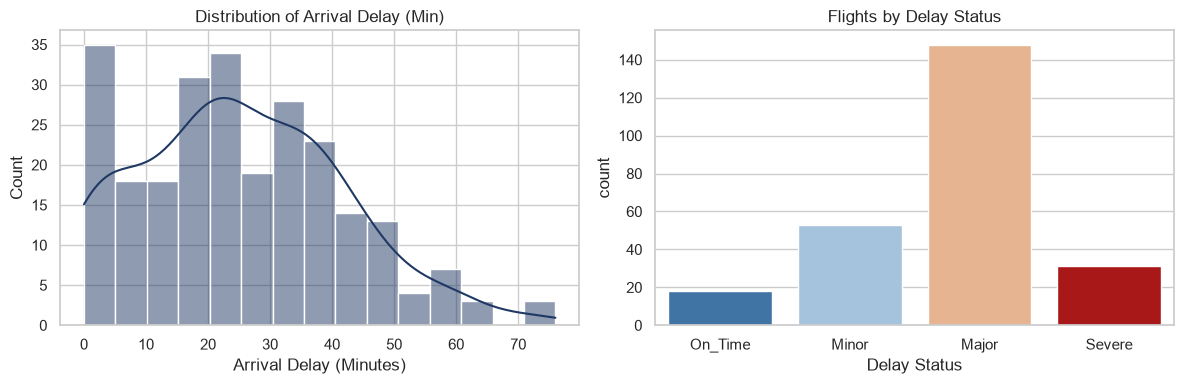

In [7]:
delays = clean_df['Arrival_Delay_Min'].to_numpy()
print('Mean delay (min):', round(float(delays.mean()), 2))
print('Median delay (min):', float(np.median(delays)))
print('Std dev (min):', round(float(delays.std()), 2))
print('Min / Max (min):', int(delays.min()), '/', int(delays.max()))
print('Percentiles (25, 50, 75):', np.percentile(delays, [25, 50, 75]))
print('\nFlight counts by Delay_Status:')
print(clean_df['Delay_Status'].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_df['Arrival_Delay_Min'], bins=15, kde=True, color='#1F3864', ax=ax[0])
ax[0].set_title('Distribution of Arrival Delay (Min)')
ax[0].set_xlabel('Arrival Delay (Minutes)')

order = ['On_Time', 'Minor', 'Major', 'Severe']
sns.countplot(data=clean_df, x='Delay_Status', order=order,
              palette=['#2E75B6', '#9DC3E6', '#F4B183', '#C00000'], ax=ax[1])
ax[1].set_title('Flights by Delay Status')
ax[1].set_xlabel('Delay Status')
plt.tight_layout()
plt.savefig('../images/01_overall_delay.png')
plt.show()


### Q2. Do Passengers and Turnaround_Time_Min affect Arrival_Delay_Min?


Correlation with Arrival_Delay_Min:
Arrival_Delay_Min        1.000
Passengers               0.570
Turnaround_Time_Min     -0.508
Distance_Km              0.019
Crew_Experience_Years    0.038
Avg_Ticket_Fare_INR      0.033
Revenue_Estimate_INR     0.466
Name: Arrival_Delay_Min, dtype: float64


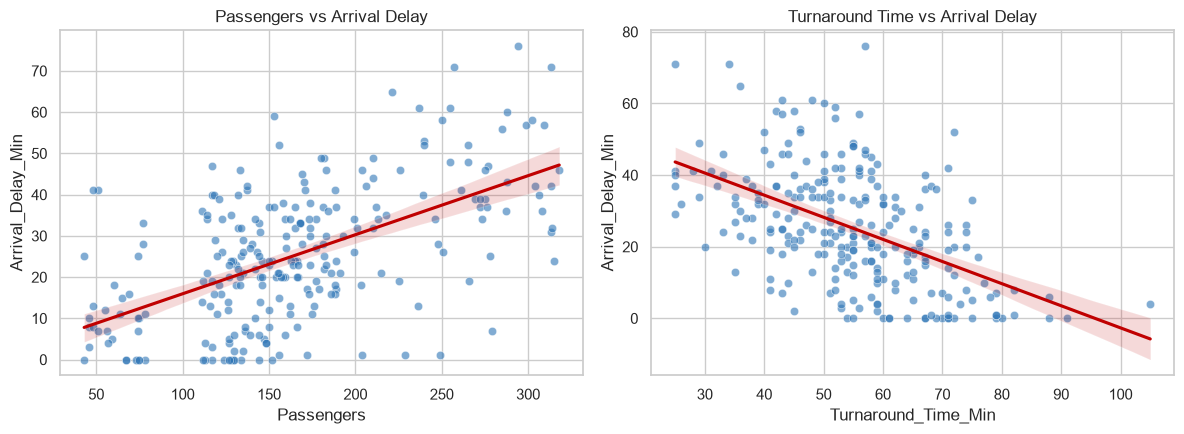

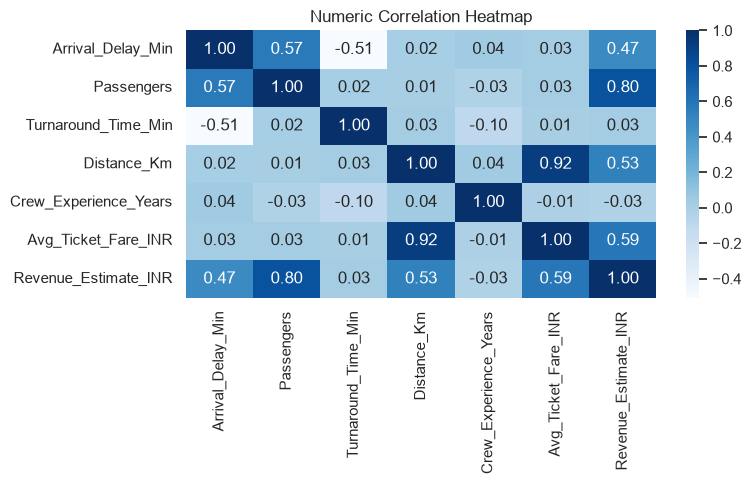

In [8]:
num_cols = [
    'Arrival_Delay_Min', 'Passengers', 'Turnaround_Time_Min',
    'Distance_Km', 'Crew_Experience_Years', 'Avg_Ticket_Fare_INR', 'Revenue_Estimate_INR'
]
print('Correlation with Arrival_Delay_Min:')
print(clean_df[num_cols].corr()['Arrival_Delay_Min'].round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=clean_df, x='Passengers', y='Arrival_Delay_Min', alpha=0.6, color='#2E75B6', ax=ax[0])
sns.regplot(data=clean_df, x='Passengers', y='Arrival_Delay_Min', scatter=False, color='#C00000', ax=ax[0])
ax[0].set_title('Passengers vs Arrival Delay')

sns.scatterplot(data=clean_df, x='Turnaround_Time_Min', y='Arrival_Delay_Min', alpha=0.6, color='#2E75B6', ax=ax[1])
sns.regplot(data=clean_df, x='Turnaround_Time_Min', y='Arrival_Delay_Min', scatter=False, color='#C00000', ax=ax[1])
ax[1].set_title('Turnaround Time vs Arrival Delay')
plt.tight_layout()
plt.savefig('../images/02_passengers_turnaround.png')
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(clean_df[num_cols].corr().round(2), annot=True, cmap='Blues', fmt='.2f')
plt.title('Numeric Correlation Heatmap')
plt.tight_layout()
plt.savefig('../images/03_correlation.png')
plt.show()


### Q3. Does Arrival_Delay_Min differ by Origin_City, Aircraft_Type, Departure_Slot, and Weather_Condition?


=== Origin_City ===
  Bengaluru    | n=39  | mean=22.62 | median=23.0
  Hyderabad    | n=41  | mean=30.49 | median=30.0
  Mumbai       | n=72  | mean=25.69 | median=25.5
  Kolkata      | n=26  | mean=22.88 | median=22.0
  Delhi        | n=72  | mean=24.29 | median=22.5
=== Aircraft_Type ===
  Narrow_Body  | n=154 | mean=22.47 | median=23.0
  Wide_Body    | n=64  | mean=39.00 | median=39.0
  Turboprop    | n=32  | mean=11.53 | median=9.0
=== Departure_Slot ===
  Night        | n=43  | mean=24.49 | median=26.0
  Morning      | n=83  | mean=26.96 | median=24.0
  Afternoon    | n=65  | mean=26.80 | median=25.0
  Evening      | n=59  | mean=21.92 | median=20.0
=== Weather_Condition ===
  Clear        | n=131 | mean=22.92 | median=23.0
  Rain         | n=38  | mean=31.34 | median=33.0
  Fog          | n=16  | mean=35.12 | median=36.5
  Cloudy       | n=65  | mean=24.15 | median=24.0
=== Distance_Band ===
  Medium       | n=119 | mean=26.00 | median=25.0
  Short        | n=76  | mean=23.88 | 

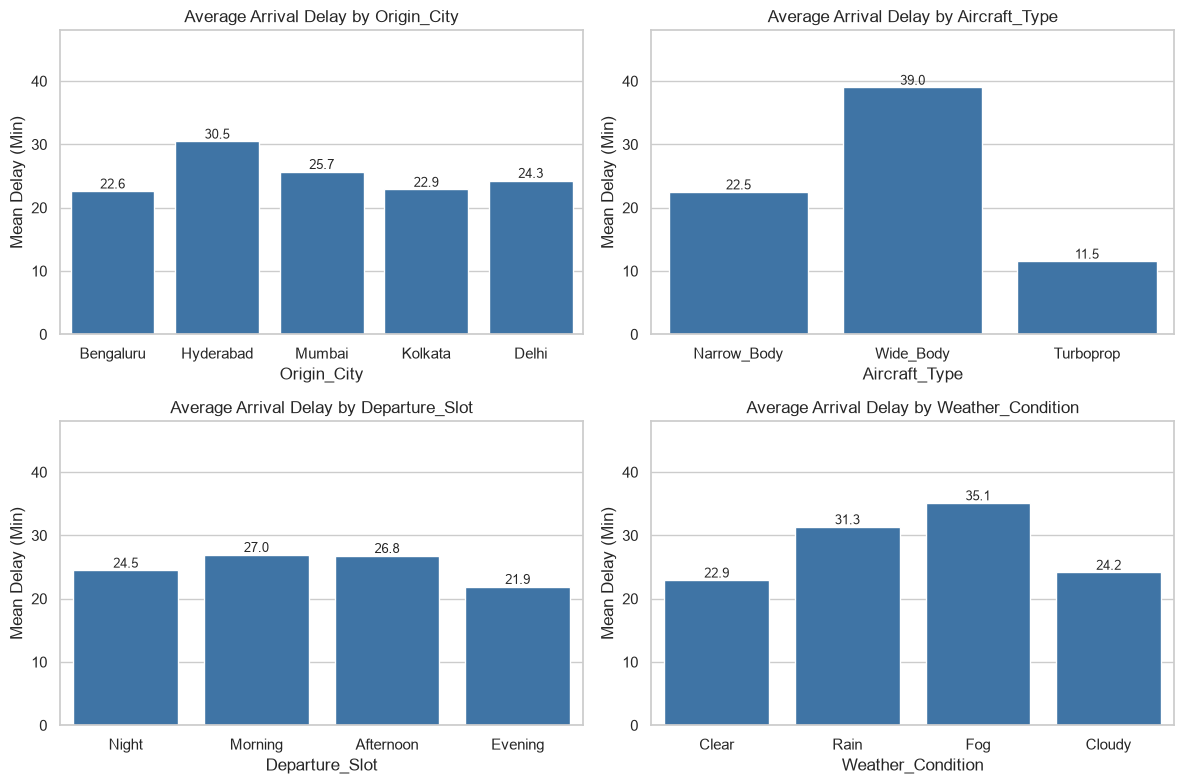

In [9]:
cat_cols = ['Origin_City', 'Aircraft_Type', 'Departure_Slot', 'Weather_Condition']
for col in cat_cols + ['Distance_Band']:
    print(f'=== {col} ===')
    for val in clean_df[col].unique():
        vals = clean_df.loc[clean_df[col] == val, 'Arrival_Delay_Min'].to_numpy()
        print(f'  {val:<12} | n={len(vals):<3} | mean={vals.mean():.2f} | median={np.median(vals):.1f}')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col in zip(ax.flat, cat_cols):
    sns.barplot(data=clean_df, x=col, y='Arrival_Delay_Min', errorbar=None, color='#2E75B6', ax=a)
    a.set_title(f'Average Arrival Delay by {col}')
    a.set_ylabel('Mean Delay (Min)')
    a.set_ylim(0, 48)
    for p in a.patches:
        a.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()),
                   ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('../images/04_group_comparison.png')
plt.show()


### Q4. Which flights need attention? (At Risk: Arrival_Delay_Min >= 45)


In [10]:
at_risk_df = clean_df[clean_df['At_Risk'] == 'Yes'].sort_values('Arrival_Delay_Min', ascending=False)
print(f'Total At Risk flights: {len(at_risk_df)} / {len(clean_df)} ({len(at_risk_df)/len(clean_df)*100:.1f}%)')

for col in cat_cols + ['Distance_Band']:
    print(f'\n--- At Risk Rate by {col} ---')
    for val in clean_df[col].unique():
        sub = clean_df[clean_df[col] == val]
        risk_n = (sub['At_Risk'] == 'Yes').sum()
        print(f'  {val:<12} | {risk_n:>2}/{len(sub):<3} ({risk_n/len(sub)*100:5.1f}%)')

at_risk_df[['Flight_ID', 'Origin_City', 'Aircraft_Type', 'Departure_Slot', 'Weather_Condition', 'Passengers', 'Turnaround_Time_Min', 'Arrival_Delay_Min']].head(10)


Total At Risk flights: 31 / 250 (12.4%)

--- At Risk Rate by Origin_City ---
  Bengaluru    |  3/39  (  7.7%)
  Hyderabad    |  9/41  ( 22.0%)
  Mumbai       |  9/72  ( 12.5%)
  Kolkata      |  2/26  (  7.7%)
  Delhi        |  8/72  ( 11.1%)

--- At Risk Rate by Aircraft_Type ---
  Narrow_Body  |  8/154 (  5.2%)
  Wide_Body    | 23/64  ( 35.9%)
  Turboprop    |  0/32  (  0.0%)

--- At Risk Rate by Departure_Slot ---
  Night        |  3/43  (  7.0%)
  Morning      | 10/83  ( 12.0%)
  Afternoon    |  8/65  ( 12.3%)
  Evening      | 10/59  ( 16.9%)

--- At Risk Rate by Weather_Condition ---
  Clear        | 10/131 (  7.6%)
  Rain         | 10/38  ( 26.3%)
  Fog          |  5/16  ( 31.2%)
  Cloudy       |  6/65  (  9.2%)

--- At Risk Rate by Distance_Band ---
  Medium       | 17/119 ( 14.3%)
  Short        |  8/76  ( 10.5%)
  Long         |  6/55  ( 10.9%)


,Flight_ID,Origin_City,Aircraft_Type,Departure_Slot,Weather_Condition,Passengers,Turnaround_Time_Min,Arrival_Delay_Min
61,F1013,Delhi,Wide_Body,Morning,Fog,294,57,76
18,F1036,Bengaluru,Wide_Body,Night,Rain,257,25,71
86,F1027,Delhi,Wide_Body,Afternoon,Rain,313,34,71
239,F1098,Hyderabad,Wide_Body,Afternoon,Clear,221,36,65
186,F1223,Hyderabad,Wide_Body,Morning,Cloudy,255,48,61
209,F1083,Hyderabad,Wide_Body,Morning,Rain,237,43,61
166,F1043,Delhi,Wide_Body,Morning,Cloudy,288,50,60
175,F1084,Hyderabad,Narrow_Body,Evening,Fog,153,52,59
91,F1220,Kolkata,Wide_Body,Morning,Rain,250,42,58
217,F1157,Delhi,Wide_Body,Morning,Clear,302,45,58


## 7. Key Insights & Recommendations
- **Overall Distribution:** Average delay is **25.3 min** (median **24.0 min**, std dev **16.4 min**), ranging from **0 to 76 min** with a slight right tail of severe delays.
- **Turnaround & Passenger Load:** Flights with **shorter turnaround times** (`r = -0.51`) and **higher passenger loads** (`r = +0.57`) experience noticeably longer delays.
- **Aircraft & Weather Impact:** **Wide-body aircraft** average **39.0 min** delay (`35.9%` At Risk), and **Fog** (`35.1 min` avg, `31.2%` At Risk) and **Rain** (`31.3 min` avg, `26.3%` At Risk) drive major spikes.
- **Actionable Focus:** Prioritize buffer turnaround time for high-load **Wide-Body** flights and build weather contingency buffers at **Hyderabad** and during **Fog/Rain** windows.


## 8. Save the Cleaned Dataset


In [11]:
clean_df.to_csv('../data/processed/flights_data_clean.csv', index=False)
print('Saved flights_data_clean.csv with', len(clean_df), 'rows and', clean_df.shape[1], 'columns.')


Saved flights_data_clean.csv with 250 rows and 16 columns.
